<a href="https://colab.research.google.com/github/apiswrld/UTS-Data-Mining/blob/main/UTS_DataMining_WineQuality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UTS Data Mining – Klasifikasi Kualitas Anggur (Wine Quality)
**Mata kuliah:** Data Mining | **Prodi:** D3 Staterkom, UNNES | **Sifat:** Take Home Test

**Tujuan:** membangun model klasifikasi untuk memprediksi `quality` anggur dari fitur kimiawi, lalu menerapkannya pada `data_testing.csv`.

**Alur:** 1) Persiapan data → 2) Pembersihan data & feature scaling → 3) Pembuatan & evaluasi model → 4) Prediksi data uji → 5) Penyimpanan hasil.

## 1. Persiapan Data

In [46]:
import pandas as pd, numpy as np, warnings, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
warnings.filterwarnings('ignore')
RS = 42
PATH = ''

train = pd.read_csv(PATH + 'data_training.csv')
test  = pd.read_csv(PATH + 'data_testing.csv')
print('Training:', train.shape, '| Testing:', test.shape)
train.head()

Training: (857, 13) | Testing: (286, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


Data training berisi 857 sampel dengan 11 fitur kimiawi, kolom target `quality`, dan kolom `Id`. Data testing berisi 286 sampel dengan struktur yang sama **tanpa** `quality`. `Id` hanya pengenal baris, sehingga **tidak dipakai sebagai fitur** (agar model tidak belajar dari nomor baris).

## 2. Pembersihan Data

### 2.1 Missing values & duplikat

In [47]:
print('Missing values training:', train.isna().sum().sum())
print('Missing values testing :', test.isna().sum().sum())
print('Baris duplikat training:', train.drop(columns='Id').duplicated().sum())
print('Id unik training:', train.Id.is_unique, '| Id unik testing:', test.Id.is_unique)
print('Id training & testing tidak tumpang tindih:', len(set(train.Id) & set(test.Id)) == 0)

Missing values training: 0
Missing values testing : 0
Baris duplikat training: 76
Id unik training: True | Id unik testing: True
Id training & testing tidak tumpang tindih: True


**Interpretasi:** tidak ada nilai yang hilang pada kedua dataset sehingga imputasi/penghapusan data tidak diperlukan. `Id` unik serta tidak tumpang tindih antara training dan testing.

Namun terdapat **76 baris duplikat** (fitur dan `quality` identik) pada data training. Duplikat bisa membuat evaluasi terlalu optimistis: baris yang sama dapat jatuh di data latih *dan* data validasi sehingga model seolah-olah "menebak" data yang sudah dihafalnya. Penanganan: **evaluasi dan pemilihan model dilakukan pada data tanpa duplikat** (bagian 3.1), sedangkan model akhir dilatih pada seluruh data training karena duplikat bisa saja merupakan sampel nyata yang memang muncul berulang.

### 2.2 Distribusi target

quality
3      6
4     26
5    362
6    341
7    109
8     13
Name: count, dtype: int64


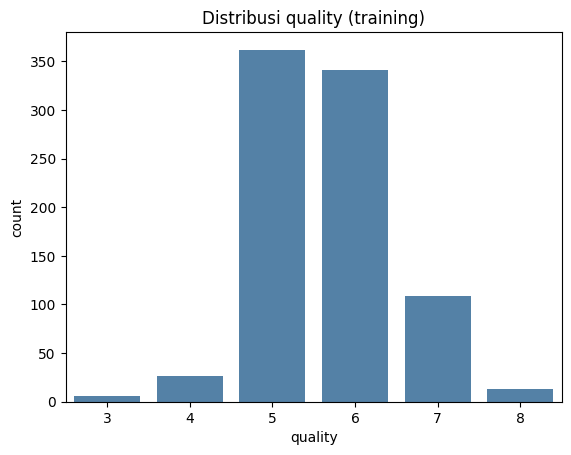

In [48]:
print(train.quality.value_counts().sort_index())
sns.countplot(x='quality', data=train, color='steelblue'); plt.title('Distribusi quality (training)'); plt.show()

**Interpretasi:** kelas sangat tidak seimbang. Nilai 5 dan 6 mendominasi, sedangkan kelas 3, 4, dan 8 sangat jarang (6, 26, dan 13 sampel). Akibatnya model cenderung baik pada kelas mayoritas dan lemah pada kelas langka. Karena itu akurasi dilengkapi dengan confusion matrix dan classification report, dan pembagian data memakai *stratified*.

### 2.3 Statistik deskriptif & kebutuhan feature scaling

In [49]:
features = [c for c in train.columns if c not in ('quality','Id')]
display(train[features].describe().T[['min','max','mean','std']].round(4))

,min,max,mean,std
fixed acidity,4.6000,15.6000,8.2620,1.7020
volatile acidity,0.1200,1.5800,0.5294,0.1792
citric acid,0.0000,1.0000,0.2674,0.1951
residual sugar,0.9000,15.5000,2.5062,1.2935
chlorides,0.0120,0.6110,0.0868,0.0487
free sulfur dioxide,1.0000,68.0000,15.7830,10.3004
total sulfur dioxide,6.0000,278.0000,45.9784,31.6921
density,0.9901,1.0032,0.9967,0.0019
pH,2.7400,4.0100,3.3131,0.1521
sulphates,0.3900,2.0000,0.6567,0.1674


**Interpretasi:** skala fitur sangat berbeda. `total sulfur dioxide` mencapai ratusan, sedangkan `density` hanya sekitar 0,99–1,00 dan `chlorides` di bawah 1. Model berbasis jarak/gradien (KNN, SVM, Regresi Logistik) sensitif terhadap hal ini, sehingga **feature scaling (StandardScaler) diperlukan untuk model tersebut**. Model berbasis pohon (Decision Tree, Random Forest) tidak terpengaruh skala. Scaler dimasukkan ke dalam `Pipeline` sehingga hanya dipelajari dari data latih di setiap fold (tidak ada kebocoran).

### 2.4 Korelasi antar fitur dengan quality

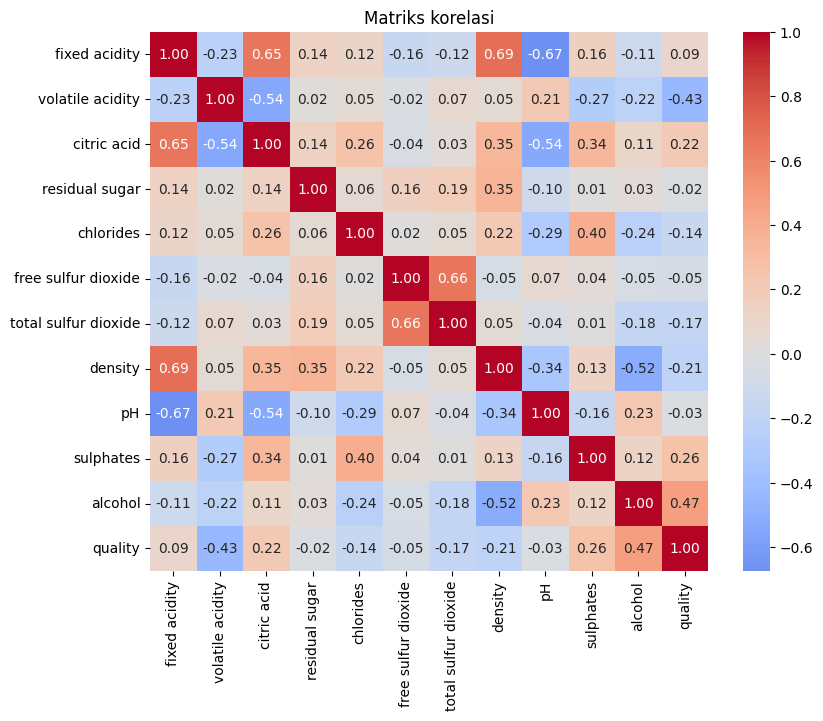

alcohol                 0.474
sulphates               0.261
citric acid             0.221
fixed acidity           0.093
residual sugar         -0.021
pH                     -0.033
free sulfur dioxide    -0.055
chlorides              -0.145
total sulfur dioxide   -0.173
density                -0.208
volatile acidity       -0.430
Name: quality, dtype: float64


In [50]:
corr = train[features + ['quality']].corr()
plt.figure(figsize=(9,7)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.title('Matriks korelasi'); plt.show()
print(corr['quality'].drop('quality').sort_values(ascending=False).round(3))

**Interpretasi:** `alcohol` memiliki korelasi positif terkuat dengan `quality`; `volatile acidity` berkorelasi negatif, dan `sulphates` serta `citric acid` cenderung positif. Artinya anggur dengan kadar alkohol lebih tinggi dan keasaman volatil lebih rendah cenderung berkualitas lebih baik. Korelasi antar fitur seperti `fixed acidity`–`density`–`citric acid`–`pH` cukup tinggi (multikolinearitas), yang lebih mengganggu model linear daripada model pohon.

## 3. Pembuatan Model

### 3.1 Pembagian data latih/validasi

In [51]:
X = train[features]; y = train['quality']

train_dd = train.drop_duplicates(subset=features + ['quality'])
X_dd, y_dd = train_dd[features], train_dd['quality']
print('Training penuh:', X.shape, '| tanpa duplikat:', X_dd.shape)

X_tr, X_val, y_tr, y_val = train_test_split(X_dd, y_dd, test_size=0.2, stratify=y_dd, random_state=RS)
print('Latih:', X_tr.shape, '| Validasi:', X_val.shape)

Training penuh: (857, 11) | tanpa duplikat: (781, 11)
Latih: (624, 11) | Validasi: (157, 11)


Data tanpa duplikat dibagi 80% (latih) dan 20% (validasi) secara stratified. Data validasi dipakai untuk mengukur kinerja pada data yang belum dilihat model, sehingga tidak terlalu optimistis seperti akurasi pada data latih.

### 3.2 Perbandingan beberapa model (5-fold Stratified CV)

Extra Trees            0.5897
Random Forest          0.5752
Logistic Regression    0.5721
SVM (RBF)              0.5704
KNN (k=15)             0.5304
Gradient Boosting      0.5175
Decision Tree          0.5064
dtype: float64


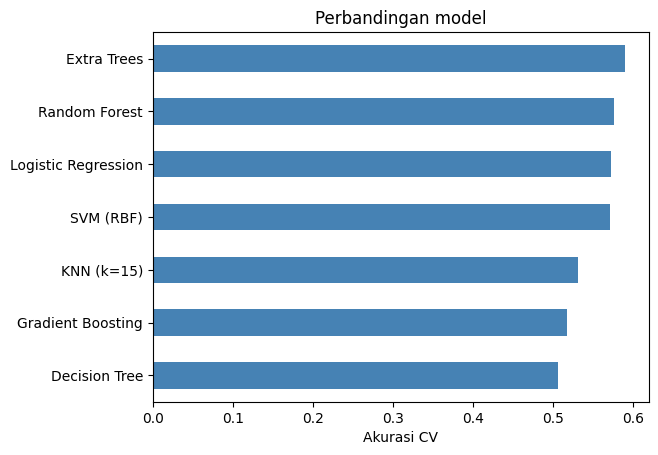

In [52]:
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
scaled = lambda m: Pipeline([('scaler', StandardScaler()), ('model', m)])
models = {
 'Decision Tree'      : DecisionTreeClassifier(max_depth=5, random_state=RS),
 'Logistic Regression': scaled(LogisticRegression(max_iter=2000)),
 'KNN (k=15)'         : scaled(KNeighborsClassifier(15)),
 'SVM (RBF)'          : scaled(SVC(C=1)),
 'Gradient Boosting'  : GradientBoostingClassifier(random_state=RS),
 'Extra Trees'        : ExtraTreesClassifier(200, random_state=RS),
 'Random Forest'      : RandomForestClassifier(200, random_state=RS),
}
res = {k: cross_val_score(v, X_tr, y_tr, cv=cv).mean() for k, v in models.items()}
res = pd.Series(res).sort_values(ascending=False)
print(res.round(4))
res.sort_values().plot(kind='barh', color='steelblue'); plt.xlabel('Akurasi CV'); plt.title('Perbandingan model'); plt.show()

**Interpretasi:** Extra Trees dan Random Forest berada di posisi teratas, diikuti dekat oleh Regresi Logistik dan SVM, sedangkan Decision Tree tunggal, KNN, dan Gradient Boosting (dengan pengaturan standar) lebih rendah. Selisih antar model papan atas kecil (sekitar 1–2 poin persen), sehingga tidak ada model yang unggul telak; ini mencerminkan batas informasi pada 11 fitur kimiawi dan penilaian kualitas yang subjektif. **Random Forest dipilih** sebagai model utama karena kinerjanya kompetitif, stabil, tidak memerlukan scaling, dan memberi feature importance yang mudah diinterpretasi; hiperparameternya kemudian di-tuning.

### 3.3 Tuning hyperparameter Random Forest

In [53]:
param_dist = {
    'n_estimators'     : [200, 300, 500],
    'max_depth'        : [None, 10, 15, 20],
    'min_samples_leaf' : [1, 2, 3],
    'max_features'     : ['sqrt', 'log2', 0.5],
    'class_weight'     : [None, 'balanced_subsample'],
}
search = RandomizedSearchCV(RandomForestClassifier(random_state=RS), param_dist, n_iter=12,
                            cv=cv, scoring='accuracy', random_state=RS, n_jobs=1)
search.fit(X_tr, y_tr)
print('Parameter terbaik:', search.best_params_)
print('Akurasi CV terbaik:', round(search.best_score_, 4))

Parameter terbaik: {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10, 'class_weight': 'balanced_subsample'}
Akurasi CV terbaik: 0.5913


Pencarian acak (RandomizedSearchCV) dengan 5-fold CV dipakai untuk memilih kombinasi parameter yang memberi akurasi validasi silang tertinggi. Pencarian dilakukan hanya pada data latih (80%), sehingga data validasi tetap bersih.

### 3.4 Evaluasi model pada data latih vs validasi

Akurasi data latih   : 0.9551
Akurasi data validasi: 0.5732

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.66      0.71      0.69        66
           6       0.52      0.55      0.53        62
           7       0.50      0.45      0.47        20
           8       0.00      0.00      0.00         3

    accuracy                           0.57       157
   macro avg       0.28      0.29      0.28       157
weighted avg       0.55      0.57      0.56       157



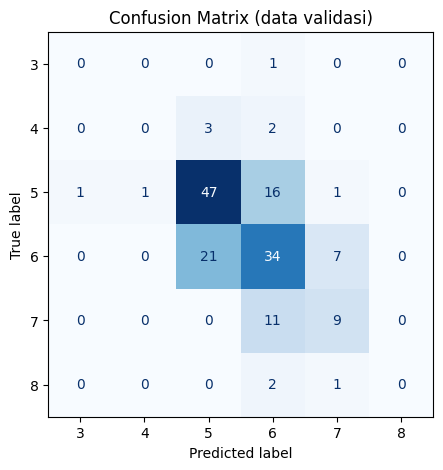

In [54]:
best = search.best_estimator_
pred_tr  = best.predict(X_tr)
pred_val = best.predict(X_val)
print('Akurasi data latih   :', round(accuracy_score(y_tr,  pred_tr), 4))
print('Akurasi data validasi:', round(accuracy_score(y_val, pred_val), 4))
print()
print(classification_report(y_val, pred_val, zero_division=0))
labels = sorted(y.unique())
fig, ax = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred_val, labels=labels), display_labels=labels).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix (data validasi)'); plt.show()

**Interpretasi:**
- Akurasi data latih (sekitar 95%) jauh lebih tinggi daripada validasi (sekitar 57%). Ini wajar pada Random Forest (pohon dalam hampir "menghafal" data latih), sehingga **akurasi validasi/CV adalah ukuran yang jujur** untuk memperkirakan kinerja pada data uji.
- Confusion matrix menunjukkan model paling baik memprediksi kelas 5 dan 6. Kesalahan terutama terjadi antar kelas bersebelahan (5↔6, 6↔7), yang masuk akal karena perbedaan kualitas yang tipis dan penilaian anggur bersifat subjektif.
- Kelas langka (3, 4, 8) sangat sulit diprediksi karena contohnya hanya segelintir (data validasi hanya memuat 1–5 sampel per kelas tersebut). Ini keterbatasan data, bukan semata kesalahan model.

### 3.5 Fitur yang paling berpengaruh

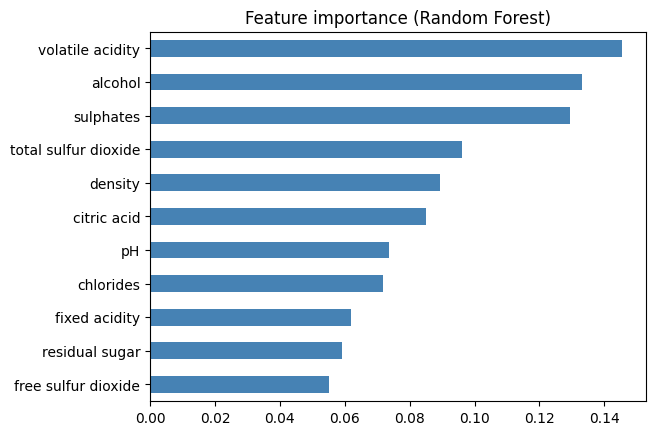

volatile acidity        0.146
alcohol                 0.133
sulphates               0.129
total sulfur dioxide    0.096
density                 0.089
citric acid             0.085
pH                      0.074
chlorides               0.072
fixed acidity           0.062
residual sugar          0.059
free sulfur dioxide     0.055
dtype: float64


In [55]:
imp = pd.Series(best.feature_importances_, index=features).sort_values()
imp.plot(kind='barh', color='steelblue'); plt.title('Feature importance (Random Forest)'); plt.show()
print(imp.sort_values(ascending=False).round(3))

**Interpretasi:** fitur dengan kontribusi terbesar adalah `volatile acidity`, `alcohol`, `sulphates`, dan `total sulfur dioxide`, sejalan dengan analisis korelasi (kecuali bahwa `alcohol` paling kuat secara korelasi linear, sedangkan importance pohon lebih merata karena menangkap hubungan non-linear). Keasaman volatil (rasa seperti cuka) yang tinggi menurunkan kualitas, sedangkan sulphates dan alkohol yang lebih tinggi cenderung menaikkannya.

### 3.6 Model akhir: dilatih ulang pada seluruh data training & disimpan

In [56]:
final_model = RandomForestClassifier(**search.best_params_, random_state=RS)
final_model.fit(X, y)
print('Akurasi resubstitusi (hanya referensi):', round(accuracy_score(y, final_model.predict(X)), 4))
joblib.dump({'model': final_model, 'features': features}, 'model_wine_rf.joblib', compress=3)
print('Model tersimpan: model_wine_rf.joblib')

Akurasi resubstitusi (hanya referensi): 0.9557
Model tersimpan: model_wine_rf.joblib


Setelah hiperparameter dipilih, model dilatih ulang pada **seluruh** data training agar memanfaatkan semua informasi. Model disimpan dengan `joblib` sesuai instruksi soal, lalu dimuat kembali untuk deployment.

## 4. Prediksi Data Uji (Deployment)

In [57]:
saved = joblib.load('model_wine_rf.joblib')
loaded_model, feats = saved['model'], saved['features']

X_test = test[feats]
print('Missing di data testing:', X_test.isna().sum().sum())
test_pred = loaded_model.predict(X_test)

hasil = pd.DataFrame({'Id': test['Id'], 'Quality': test_pred.astype(int)})
print(hasil.shape)
print(hasil.Quality.value_counts().sort_index())
hasil.head()

Missing di data testing: 0
(286, 2)
Quality
4      2
5    126
6    116
7     41
8      1
Name: count, dtype: int64


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,7


**Interpretasi:** model yang dimuat dari file digunakan pada 286 data uji dengan urutan kolom fitur yang sama seperti saat pelatihan. Distribusi prediksi terkonsentrasi pada kelas 5 dan 6, selaras dengan distribusi data latih.

## 5. Penyimpanan Hasil Prediksi

In [58]:
out = hasil[['Id', 'Quality']].copy()
out['Quality'] = out['Quality'].astype(int)

# validasi format
assert list(out.columns) == ['Id', 'Quality']
assert len(out) == len(test) and out.Id.is_unique
assert set(out.Id) == set(test.Id)

out.to_csv('hasilprediksi_008.csv', sep=';', index=False)
print(pd.read_csv('hasilprediksi_008.csv', sep=';').head())
print('Kolom:', list(out.columns), '| Baris:', len(out))

     Id  Quality
0   222        5
1  1514        6
2   417        5
3   754        5
4   516        7
Kolom: ['Id', 'Quality'] | Baris: 286


File hasil hanya berisi dua kolom (`Id` dan `Quality`), dengan format dan pemisah titik koma yang sama seperti template, serta urutan `Id` mengikuti template. **Catatan:** ganti nama file menjadi `hasilprediksi_<3 digit terakhir NIM>.csv` sebelum dikumpulkan.

## Kesimpulan
- Data tanpa missing value; terdapat 76 duplikat yang ditangani dengan evaluasi pada data tanpa duplikat; kelas target tidak seimbang.
- Feature scaling diperlukan untuk model berbasis jarak/linear, tetapi tidak untuk Random Forest.
- Random Forest (hasil tuning) memberi akurasi validasi silang sekitar 59% pada data tanpa duplikat, kompetitif dengan model terbaik lainnya (selisih antar model papan atas kecil).
- Fitur paling berpengaruh: `volatile acidity`, `alcohol`, `sulphates`.
- Keterbatasan: kelas langka (3, 4, 8) sulit diprediksi; kinerja pada data uji diperkirakan sekitar 57–60% (mendekati akurasi CV/validasi), bukan akurasi data latih. Peningkatan lebih lanjut mungkin lewat rekayasa fitur atau penggabungan kelas.